<h1 align="center">Système de Recommandation de Cours en Ligne par Clustering</h1>

## Contexte du Projet
Ce projet développe un système de recommandation intelligent pour des cours en ligne en utilisant des techniques de clustering. L'objectif principal est de regrouper les cours similaires afin de faciliter la découverte de contenus pertinents et de personnaliser l'expérience utilisateur.

## Objectifs
- **Analyse et nettoyage** d'un dataset initial de 209,734 cours en ligne
- **Développement d'un système de clustering** pour regrouper les cours similaires
- **Amélioration des performances** avec des techniques de deep learning
- **Fourniture de recommandations personnalisées** basées sur les préférences utilisateur

## Architecture du Projet
Le système s'articule autour de trois composants principaux :

1. **Prétraitement des Données**  
   Préparation et nettoyage approfondi du dataset pour garantir la qualité des données d'entrée.

2. **Clustering**  
   Application d'algorithmes de clustering (K-Means) pour identifier des groupes de cours homogènes.

3. **Deep Learning**  
   Amélioration du clustering initial par des techniques d'apprentissage profond pour capturer des relations complexes.

## Pipeline de Prétraitement
Le processus de préparation des données suit une méthodologie rigoureuse :

- **Analyse exploratoire** : Compréhension de la structure et distribution des données
- **Gestion des doublons** : Détection et suppression des enregistrements redondants
- **Nettoyage des données** : Élimination des valeurs aberrantes et incohérentes
- **Traitement des valeurs manquantes** : Imputation ou suppression selon le contexte
- **Normalisation des types** : Conversion des variables (datetime, boolean, numeric)
- **Enrichissement** : Fusion de sources externes pour compléter les informations
- **Feature engineering** : Création et transformation de variables pertinentes
- **Vectorisation textuelle** : Transformation du texte en features numériques (TF-IDF)

## Résultat
**Dataset final** : 115,697 cours prêts pour le clustering  

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from difflib import get_close_matches
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
from sklearn.svm import LinearSVC

RANDOM_STATE=42
np.random.seed(RANDOM_STATE)

import warnings
warnings.filterwarnings('ignore')

#  1.Chargement des datasets

In [2]:
data1=pd.read_csv('Course_info.csv')
data1_cp=data1.copy()


In [3]:
data1_cp.head()

,id,title,is_paid,price,headline,num_subscribers,avg_rating,num_reviews,num_comments,num_lectures,content_length_min,published_time,last_update_date,category,subcategory,topic,language,course_url,instructor_name,instructor_url
0,4715.0,Online Vegan Vegetarian Cooking School,True,24.99,Learn to cook delicious vegan recipes. Filmed ...,2231.0,3.75,134.0,42.0,37.0,1268.0,2010-08-05T22:06:13Z,2020-11-06,Lifestyle,Food & Beverage,Vegan Cooking,English,/course/vegan-vegetarian-cooking-school/,Angela Poch,/user/angelapoch/
1,1769.0,The Lean Startup Talk at Stanford E-Corner,False,0.00,Debunking Myths of Entrepreneurship A startup ...,26474.0,4.50,709.0,112.0,9.0,88.0,2010-01-12T18:09:46Z,NaN,Business,Entrepreneurship,Lean Startup,English,/course/the-lean-startup-debunking-myths-of-en...,Eric Ries,/user/ericries/
2,5664.0,"How To Become a Vegan, Vegetarian, or Flexitarian",True,19.99,Get the tools you need for a lifestyle change ...,1713.0,4.40,41.0,13.0,14.0,82.0,2010-10-13T18:07:17Z,2019-10-09,Lifestyle,Other Lifestyle,Vegan Cooking,English,/course/see-my-personal-motivation-for-becomin...,Angela Poch,/user/angelapoch/
3,7723.0,How to Train a Puppy,True,199.99,Train your puppy the right way with Dr. Ian Du...,4988.0,4.80,395.0,88.0,36.0,1511.0,2011-06-20T20:08:38Z,2016-01-13,Lifestyle,Pet Care & Training,Pet Training,English,/course/complete-dunbar-collection/,Ian Dunbar,/user/ian-dunbar/
4,8157.0,Web Design from the Ground Up,True,159.99,Learn web design online: Everything you need t...,1266.0,4.75,38.0,12.0,38.0,569.0,2011-06-23T18:31:20Z,NaN,Design,Web Design,Web Design,English,/course/web-design-from-the-ground-up/,E Learning Lab,/user/edwin-ang-2/


In [4]:
data1_cp.shape

(209734, 20)

# **Analyse exploratoire**

In [5]:
data1_cp.columns

Index(['id', 'title', 'is_paid', 'price', 'headline', 'num_subscribers',
       'avg_rating', 'num_reviews', 'num_comments', 'num_lectures',
       'content_length_min', 'published_time', 'last_update_date', 'category',
       'subcategory', 'topic', 'language', 'course_url', 'instructor_name',
       'instructor_url'],
      dtype='object')

In [6]:
data1_cp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209734 entries, 0 to 209733
Data columns (total 20 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  209734 non-null  float64
 1   title               209734 non-null  object 
 2   is_paid             209734 non-null  bool   
 3   price               209734 non-null  float64
 4   headline            209703 non-null  object 
 5   num_subscribers     209734 non-null  float64
 6   avg_rating          209734 non-null  float64
 7   num_reviews         209734 non-null  float64
 8   num_comments        209734 non-null  float64
 9   num_lectures        209734 non-null  float64
 10  content_length_min  209734 non-null  float64
 11  published_time      209734 non-null  object 
 12  last_update_date    209597 non-null  object 
 13  category            209734 non-null  object 
 14  subcategory         209734 non-null  object 
 15  topic               208776 non-nul

D'après ces infos , il y a:


**1.   pour les types des variables**




* 1 variable "boolean" -> il faut la convertir à 0 et 1

* 8 variables :float

* 11 variables object:dont published_time et last_update_date qu'il faut les convertir en datetime


**2. Pour les valeurs manquantes :**

On constate qu'il y a des colonnes avec des valeurs manquantes





**Valeurs dupliquées**

In [7]:
data1_cp.duplicated().sum()
#il y a zero ligne dupliquée


0

In [8]:
data1_cp['title'].duplicated().sum()
#mais il y a 1477 titre redondantes

1477

In [9]:
data1_cp['title'].value_counts()
#par exemple Python for Beginners il y en a 14 cours

title
Python for Beginners                                            14
Certified Dance Therapy English Drama Story Exercise Course     14
AWS Certified Solutions Architect Associate Practice Exams      11
AWS Certified Solutions Architect Professional Practice Exam    10
English Grammar                                                  7
                                                                ..
MATLAB/SIMULINK Masterclass - From a Beginner to an Expert       1
Forex Trading Made Simple                                        1
GDScript in Game Making for domisie student                      1
Big Data Analytics con Python e Spark 2.4: il Corso Completo     1
CISSP 4 full exams #2 : All CISSP domains - 125Q /exam- 2022     1
Name: count, Length: 208257, dtype: int64

In [10]:
data1_cp[data1_cp['title']=='Python for Beginners'].head(10)

,id,title,is_paid,price,headline,num_subscribers,avg_rating,num_reviews,num_comments,num_lectures,content_length_min,published_time,last_update_date,category,subcategory,topic,language,course_url,instructor_name,instructor_url
23526,1088822.0,Python for Beginners,True,99.99,Learn Python-- The Swiss Army Knife of Coding ...,3542.0,4.350000,412.0,168.0,65.0,322.0,2017-02-01T05:39:38Z,2021-05-24,Development,Programming Languages,Python,English,/course/python-for-beginners-2017/,Dollar Design School,/user/marklassoff/
47101,1793080.0,Python for Beginners,True,19.99,Learn Fastest Growing language,98658.0,4.546413,7888.0,1016.0,78.0,654.0,2019-11-28T16:07:25Z,2019-11-27,Development,Programming Languages,Python,English,/course/python-tutorials-for-by-navinreddy/,Navin Reddy,/user/navinreddy2/
78719,2648950.0,Python for Beginners,True,2.00,Python Programming/Scripting,9.0,5.000000,1.0,0.0,23.0,324.0,2021-06-11T04:58:07Z,2021-06-10,IT & Software,Other IT & Software,Python,English,/course/python-for-beginners-oe/,Nishant Pandey,/user/nishant-pandey-14/
84632,2789636.0,Python for Beginners,False,0.00,Learn Python from Scratch,18123.0,4.000000,435.0,66.0,25.0,97.0,2020-02-05T21:42:54Z,2020-02-07,Development,Programming Languages,Python,English,/course/python-for-beginners-/,DoItWithCode Academy,/user/masteringcode/
96100,3085680.0,Python for Beginners,True,19.99,Python 101,0.0,0.000000,0.0,0.0,13.0,102.0,2020-05-15T20:48:20Z,2020-05-09,Development,Programming Languages,Python,English,/course/python-for-beginners-n/,Ryan McQuade,/user/ryan-mcquade-3/
105222,3301920.0,Python for Beginners,True,19.99,Python Programming for Beginners,1598.0,3.944444,9.0,3.0,9.0,87.0,2022-09-10T12:48:00Z,2022-09-08,Development,Programming Languages,Python,English,/course/python-for-beginners-wr/,Charles Smith,/user/charles-smith-214/
118728,3568163.0,Python for Beginners,True,19.99,"Learn Python like a Professional, Start from t...",176.0,4.100000,33.0,8.0,104.0,1193.0,2021-05-21T18:35:59Z,2022-09-13,IT & Software,Other IT & Software,Python,English,/course/python-for-beginners-part-1-free/,Mohd Daneyal Hasan Lari,/user/mohd-daneyal-hasan-lari/
119986,3589192.0,Python for Beginners,True,19.99,From Basics to Data Structure,15791.0,4.050000,156.0,12.0,63.0,384.0,2021-01-26T07:54:33Z,2021-08-22,Development,Programming Languages,Python,English,/course/python-for-beginners-t/,Sara Al-Arab,/user/sara-al-arab/
145113,3992440.0,Python for Beginners,True,1.00,New to Python Programming and Python for all,3638.0,4.000000,91.0,18.0,29.0,247.0,2021-05-04T20:56:37Z,2021-09-18,IT & Software,IT Certifications,Python,English,/course/python-for-beginners-2021-r/,Venkata Sai Mahesh Pothuguntla,/user/venkata-sai-mahesh-2/
146189,4008466.0,Python for Beginners,True,34.99,Learn Python programming from scratch with han...,4.0,0.000000,0.0,0.0,35.0,266.0,2021-05-18T07:58:22Z,2021-05-07,Development,Programming Languages,Python,English,/course/python-for-beginners-ec/,EduCarat .,/user/educarat/


Donc peut etre il y a des cours avec des titres similaires mais les sources sont différentes le plus important c'est que l'url du cours doit etre unique

In [11]:
data1_cp[data1_cp['title']=='Certified Dance Therapy English Drama Story Exercise Course'].head()

,id,title,is_paid,price,headline,num_subscribers,avg_rating,num_reviews,num_comments,num_lectures,content_length_min,published_time,last_update_date,category,subcategory,topic,language,course_url,instructor_name,instructor_url
189355,4614996.0,Certified Dance Therapy English Drama Story Ex...,True,1.0,English lessons With Dance Therapy Video lesso...,0.0,0.0,0.0,0.0,17.0,31.0,2022-03-29T17:07:18Z,2022-03-28,Health & Fitness,Dance,Dance,English,/course/certified-dance-therapy-english-drama-...,Sarita Wariyer,/user/sarita-wariyer-7/
190081,4624042.0,Certified Dance Therapy English Drama Story Ex...,True,1.0,Workshop Lessons for English language learning...,0.0,0.0,0.0,0.0,26.0,87.0,2022-04-03T01:16:00Z,2022-05-21,Health & Fitness,Dance,Dance,English,/course/certified-dance-therapy-english-drama-...,Sarita Wariyer,/user/sarita-wariyer-7/
190249,4626396.0,Certified Dance Therapy English Drama Story Ex...,True,1.0,Workshop Lessons for English language learning...,0.0,0.0,0.0,0.0,20.0,79.0,2022-04-04T17:39:31Z,2022-04-28,Health & Fitness,Dance,Dance,English,/course/certified-dance-therapy-english-drama-...,Sarita Wariyer,/user/sarita-wariyer-7/
190407,4628596.0,Certified Dance Therapy English Drama Story Ex...,True,1.0,Workshop Lessons for English language learning...,0.0,0.0,0.0,0.0,21.0,91.0,2022-04-06T19:04:12Z,2022-08-07,Teaching & Academics,Online Education,English Literature,English,/course/certified-dance-therapy-english-drama-...,Sarita Wariyer,/user/sarita-wariyer-7/
190775,4633412.0,Certified Dance Therapy English Drama Story Ex...,True,1.0,Workshop Lessons for English language learning...,0.0,0.0,0.0,0.0,24.0,72.0,2022-04-09T09:01:51Z,2022-08-01,Teaching & Academics,Online Education,English Vocabulary,English,/course/certified-dance-therapy-english-drama-...,Sarita Wariyer,/user/sarita-wariyer-7/


D'apres ces resultat on constate que ce course et redondant car il y a le meme title, headline et instructor et pour le lien une lettre est ajouté a la fin pour faire une différence mais il s'agit du meme cours

-> Donc , on supprime les cours qui ont le meme title , headline et instructor



In [12]:
#let's check
data1_cp['course_url'].duplicated().sum()
#oui effectivement il est unique


0

In [13]:
cours_redondants=data1_cp.duplicated(subset=['title','headline','instructor_name'])
cours_redondants.sum()
data1_cp.drop_duplicates(subset=['title','headline','instructor_name'],inplace=True)
# data1_cp.shape

In [14]:
data1_cp.describe()

,id,price,num_subscribers,avg_rating,num_reviews,num_comments,num_lectures,content_length_min
count,2.096900e+05,209690.000000,2.096900e+05,209690.000000,209690.000000,209690.000000,209690.000000,209690.000000
mean,3.015224e+06,81.669867,3.097204e+03,3.747423,244.396905,44.882169,36.552635,265.592064
std,1.342570e+06,117.321158,1.558280e+04,1.533466,2458.352646,355.809809,51.876036,454.488184
min,1.769000e+03,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.950514e+06,19.990000,2.600000e+01,3.800000,3.000000,1.000000,11.000000,69.000000
50%,3.292644e+06,34.990000,2.060000e+02,4.333334,17.000000,5.000000,22.000000,133.000000
75%,4.189362e+06,99.990000,1.435000e+03,4.625000,74.000000,18.000000,42.000000,289.000000
max,4.914146e+06,999.990000,1.752364e+06,5.000000,436457.000000,39040.000000,1095.000000,22570.000000


Il y a des cours avec une durée de 0 min -> à supprimer

In [15]:
(data1_cp['content_length_min']<10).sum()
#9382
(data1_cp['content_length_min']<10).mean()
#np.float64(0.04474223854261052)

0.04474223854261052

In [16]:
data1_cp=data1_cp[data1_cp['content_length_min']>10]
data1_cp.shape

(200307, 20)

In [17]:
(data1_cp['num_lectures']==10).sum()
(data1_cp['num_lectures']==10).mean()

0.03481156424887797

In [18]:
languages_counts=data1_cp['language'].value_counts()
languages_counts/len(data1_cp)


language
English       0.577693
Portuguese    0.090311
Spanish       0.085349
Turkish       0.040093
Japanese      0.034512
                ...   
Welsh         0.000005
Tatar         0.000005
Basque        0.000005
Xhosa         0.000005
Tajik         0.000005
Name: count, Length: 77, dtype: float64

In [19]:
#on va laisser juste les cours en anglais
data1_cp=data1_cp[data1_cp['language']=='English']
data1_cp.shape

(115716, 20)

In [20]:
categories=data1_cp['category'].value_counts()
categories.index.tolist()

['Development',
 'Business',
 'IT & Software',
 'Teaching & Academics',
 'Personal Development',
 'Design',
 'Health & Fitness',
 'Lifestyle',
 'Finance & Accounting',
 'Marketing',
 'Music',
 'Office Productivity',
 'Photography & Video']

In [21]:
len(categories)

13

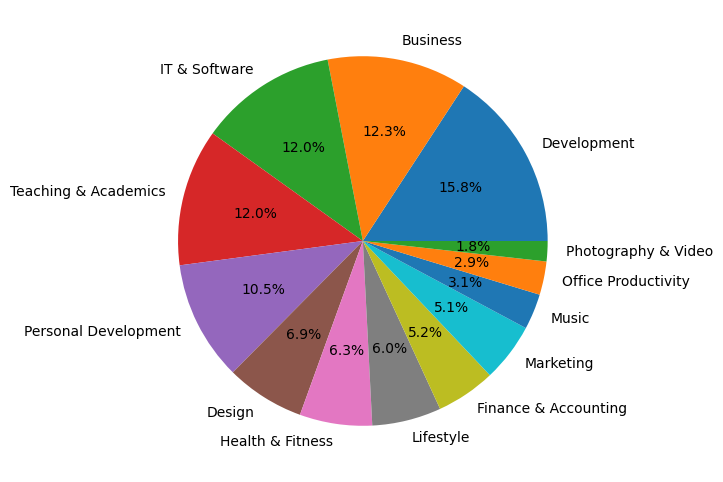

In [22]:
plt.figure(figsize=(6,6))
plt.pie(categories,labels=categories.index,autopct='%1.1f%%')
plt.show()

# Preprocessing

**Suppression des colonnes moins pertinentes (juste pour le modele)**

In [23]:
cols_a_eliminer=['course_url','instructor_url','is_paid','language']
cols_a_conserver=[col for col in data1_cp.columns if col not in cols_a_eliminer ]

In [24]:
data_model=data1_cp[cols_a_conserver]
data_model.shape

(115716, 16)

**Traitement des colonnes**

In [25]:
data_model.info()

<class 'pandas.core.frame.DataFrame'>
Index: 115716 entries, 0 to 209732
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  115716 non-null  float64
 1   title               115716 non-null  object 
 2   price               115716 non-null  float64
 3   headline            115697 non-null  object 
 4   num_subscribers     115716 non-null  float64
 5   avg_rating          115716 non-null  float64
 6   num_reviews         115716 non-null  float64
 7   num_comments        115716 non-null  float64
 8   num_lectures        115716 non-null  float64
 9   content_length_min  115716 non-null  float64
 10  published_time      115716 non-null  object 
 11  last_update_date    115592 non-null  object 
 12  category            115716 non-null  object 
 13  subcategory         115716 non-null  object 
 14  topic               115227 non-null  object 
 15  instructor_name     115713 non-null  ob

In [26]:
data_model[['published_time','last_update_date']].head()


,published_time,last_update_date
0,2010-08-05T22:06:13Z,2020-11-06
1,2010-01-12T18:09:46Z,NaN
2,2010-10-13T18:07:17Z,2019-10-09
3,2011-06-20T20:08:38Z,2016-01-13
4,2011-06-23T18:31:20Z,NaN


In [27]:
data_model['published_date'] = pd.to_datetime(data_model['published_time']).dt.date
data_model['last_update_date'] = pd.to_datetime(data_model['last_update_date']).dt.date

In [28]:
data_model.drop('published_time',axis=1,inplace=True)
data_model[['published_date','last_update_date']].head()



,published_date,last_update_date
0,2010-08-05,2020-11-06
1,2010-01-12,NaT
2,2010-10-13,2019-10-09
3,2011-06-20,2016-01-13
4,2011-06-23,NaT


**problème des dates**

on constate qu'il y a 42011 cours avec une date de publication supérieure au date de mise à jour ce qu'est illogique

In [29]:
mask=data_model['published_date']>data_model['last_update_date']
erreur_date=data_model[mask]
print(len(erreur_date))
erreur_date.head()

42011


,id,title,price,headline,num_subscribers,avg_rating,num_reviews,num_comments,num_lectures,content_length_min,last_update_date,category,subcategory,topic,instructor_name,published_date
267,20702.0,Planning Your Podcast,49.99,Learn how to create a podcast properly. These ...,324.0,4.500000,25.0,13.0,37.0,163.0,2013-04-01,Business,Media,Podcasting,Dave Jackson,2013-04-02
292,21282.0,Pythonic Python Part I: The Basics,19.99,"Fast and fun python lectures for programmers, ...",527.0,3.700000,38.0,14.0,28.0,183.0,2013-02-23,Development,Programming Languages,Python,"Marilyn Davis, Ph.D.",2013-02-25
315,22521.0,Training the Athletic Brain,34.99,Unique brain training course that relates rese...,318.0,4.100000,41.0,8.0,34.0,359.0,2013-03-27,Health & Fitness,Sports,Brain Training,Sean Fyfe,2013-03-28
386,24653.0,Startup Attention and PR 101,0.00,How to Launch a Product - Learn Marketing and ...,3250.0,4.200000,115.0,28.0,19.0,315.0,2012-11-04,Marketing,Public Relations,Startup,Ben Parr,2012-11-08
390,24599.0,Find Me A Job: How to Score a Job Before Your ...,49.99,Finding internships for college students is no...,96.0,4.857143,7.0,1.0,28.0,171.0,2012-11-12,Personal Development,Career Development,Job Search,Heather Huhman,2012-11-13


In [ ]:

data_model['published_date']=np.where(mask,data_model['last_update_date'],data_model['published_date'])
data_model['last_update_date']=np.where(mask,data_model['published_date'],data_model['last_update_date'])



In [31]:
print(len(data_model))


115716


**Gestion des valeurs manquantes**

In [32]:
missing=data_model.isnull().sum()
missing[missing>0].sort_values(ascending=False)


topic               489
last_update_date    124
headline             19
instructor_name       3
dtype: int64

suggestions

* on  va remplacer les topics manquants par subcategory
* last_update_date par published time par published_time
* headline par le titre
* instructor name par anonymous


In [33]:
data_model['topic'].fillna(data_model['subcategory'],inplace=True)
data_model['instructor_name'].fillna('anonymous',inplace=True)
data_model['headline'].fillna(data_model['title'],inplace=True)
data_model['last_update_date'].fillna(data_model['published_date'],inplace=True)



In [34]:
missing=data_model.isnull().sum()
missing[missing>0].sort_values(ascending=False)

Series([], dtype: int64)

In [35]:
summary = pd.DataFrame({
    'missing_values': data_model.isna().sum(),
    'duplicate_values': data_model.duplicated().sum()
})

summary


,missing_values,duplicate_values
id,0,0
title,0,0
price,0,0
headline,0,0
num_subscribers,0,0
avg_rating,0,0
num_reviews,0,0
num_comments,0,0
num_lectures,0,0
content_length_min,0,0


Afin d’enrichir le dataset principal, qui ne contenait pas l’information relative au niveau des cours (level), une opération de fusion (merge) a été réalisée avec le fichier udemy.csv

In [36]:
data2=pd.read_csv('Udemy.csv')

In [37]:
data2.head()

,title,description,instructor,rating,reviewcount,duration,lectures,level
0,The Complete Python Bootcamp From Zero to Hero...,Learn Python like a Professional Start from t...,Jose Portilla,4.6,486391,22 total hours,156 lectures,All Levels
1,The Complete 2023 Web Development Bootcamp,Become a Full-Stack Web Developer with just ON...,Dr. Angela Yu,4.7,338555,63 total hours,380 lectures,All Levels
2,The Web Developer Bootcamp 2023,10 Hours of React just added. Become a Develop...,Colt Steele,4.7,266527,74 total hours,722 lectures,All Levels
3,100 Days of Code: The Complete Python Pro Boot...,Master Python by building 100 projects in 100 ...,Dr. Angela Yu,4.7,251585,58 total hours,636 lectures,All Levels
4,React - The Complete Guide 2023 (incl. React R...,Dive in and learn React.js from scratch! Learn...,"Academind by Maximilian Schwarzmüller, Maximil...",4.6,199663,74.5 total hours,739 lectures,All Levels


In [38]:
data2.shape

(26256, 8)

In [39]:
data2.columns

Index(['title', 'description', 'instructor', 'rating', 'reviewcount',
       'duration', 'lectures', 'level'],
      dtype='object')

In [40]:
total_duplicates=data2.duplicated().sum()
total_duplicates
data2.drop_duplicates(inplace=True)


In [41]:
# Compter les occurrences de chaque combinaison title+instructor
combinaisons_counts = data2.groupby(['title','instructor']).size().reset_index(name='count')
combinaisons_counts.nunique()
doublons = combinaisons_counts[combinaisons_counts['count'] > 1]
len(doublons)
#413 doublons
doublons.head()


,title,instructor,count
10504,How To Make A Wordpress Website -Elementor Pag...,Darrel Wilson,2
19541,React Front To Back,Brad Traversy,2
25721,iGCBT™ Certified CBT Practitioner,"Matthew Barnett, HeadgearLabs™ Personal & Prof...",2


In [42]:
data2[data2['title']=='iGCBT™ Certified CBT Practitioner']

,title,description,instructor,rating,reviewcount,duration,lectures,level
22891,iGCBT™ Certified CBT Practitioner,Become an Internationally Certified CBT - Cogn...,"Matthew Barnett, HeadgearLabs™ Personal & Prof...",4.5,2041,17.5 total hours,228 lectures,All Levels
23396,iGCBT™ Certified CBT Practitioner,Become an Internationally Certifed CBT Cogniti...,"Matthew Barnett, HeadgearLabs™ Personal & Prof...",4.7,348,17 total hours,228 lectures,All Levels


In [43]:
data2.drop_duplicates(subset=['title'],inplace=True)

In [44]:
data2.shape

(25799, 8)

In [45]:
data2[data2['title']=='iGCBT™ Certified CBT Practitioner']

,title,description,instructor,rating,reviewcount,duration,lectures,level
22891,iGCBT™ Certified CBT Practitioner,Become an Internationally Certified CBT - Cogn...,"Matthew Barnett, HeadgearLabs™ Personal & Prof...",4.5,2041,17.5 total hours,228 lectures,All Levels


La fusion des datasets a été réalisée à l’aide d’une clé composée des attributs instructor et title. Toutefois, le dataset principal contenait la colonne instructor_name au lieu de instructor. Afin d’assurer la cohérence des clés de jointure et garantir une fusion correcte, la colonne instructor_name a été renommée en instructor avant l’opération de merge.

In [46]:
data_model.rename(columns={'instructor_name':'instructor'},inplace=True)

In [47]:
data_complet = pd.merge(
    data_model,
    data2[['title', 'instructor', 'level']],
    on=['title', 'instructor'],
    how='left'

)


In [48]:
data_complet.head()

,id,title,price,headline,num_subscribers,avg_rating,num_reviews,num_comments,num_lectures,content_length_min,last_update_date,category,subcategory,topic,instructor,published_date,level
0,4715.0,Online Vegan Vegetarian Cooking School,24.99,Learn to cook delicious vegan recipes. Filmed ...,2231.0,3.75,134.0,42.0,37.0,1268.0,2020-11-06,Lifestyle,Food & Beverage,Vegan Cooking,Angela Poch,2010-08-05,NaN
1,1769.0,The Lean Startup Talk at Stanford E-Corner,0.00,Debunking Myths of Entrepreneurship A startup ...,26474.0,4.50,709.0,112.0,9.0,88.0,2010-01-12,Business,Entrepreneurship,Lean Startup,Eric Ries,2010-01-12,NaN
2,5664.0,"How To Become a Vegan, Vegetarian, or Flexitarian",19.99,Get the tools you need for a lifestyle change ...,1713.0,4.40,41.0,13.0,14.0,82.0,2019-10-09,Lifestyle,Other Lifestyle,Vegan Cooking,Angela Poch,2010-10-13,NaN
3,7723.0,How to Train a Puppy,199.99,Train your puppy the right way with Dr. Ian Du...,4988.0,4.80,395.0,88.0,36.0,1511.0,2016-01-13,Lifestyle,Pet Care & Training,Pet Training,Ian Dunbar,2011-06-20,NaN
4,8157.0,Web Design from the Ground Up,159.99,Learn web design online: Everything you need t...,1266.0,4.75,38.0,12.0,38.0,569.0,2011-06-23,Design,Web Design,Web Design,E Learning Lab,2011-06-23,NaN


In [49]:
data_complet.columns

Index(['id', 'title', 'price', 'headline', 'num_subscribers', 'avg_rating',
       'num_reviews', 'num_comments', 'num_lectures', 'content_length_min',
       'last_update_date', 'category', 'subcategory', 'topic', 'instructor',
       'published_date', 'level'],
      dtype='object')

In [50]:
data_complet.shape

(115716, 17)

In [51]:
data_complet.isnull().sum().sort_values(ascending=False)

level                 98875
content_length_min        0
published_date            0
instructor                0
topic                     0
subcategory               0
category                  0
last_update_date          0
id                        0
title                     0
num_comments              0
num_reviews               0
avg_rating                0
num_subscribers           0
headline                  0
price                     0
num_lectures              0
dtype: int64

In [52]:
data_complet['level'].isna().mean()

0.8544626499360504

Étant donné le taux élevé de valeurs manquantes dans la colonne level atteignant environ 0.864 (soit 86,4 % des observations)., l’étape suivante du travail consiste à prédire les niveaux manquants à l’aide d’un modèle de machine learning, en exploitant les autres caractéristiques disponibles des cours.

<h1>predire level</h1>

In [53]:
data_complet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115716 entries, 0 to 115715
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  115716 non-null  float64
 1   title               115716 non-null  object 
 2   price               115716 non-null  float64
 3   headline            115716 non-null  object 
 4   num_subscribers     115716 non-null  float64
 5   avg_rating          115716 non-null  float64
 6   num_reviews         115716 non-null  float64
 7   num_comments        115716 non-null  float64
 8   num_lectures        115716 non-null  float64
 9   content_length_min  115716 non-null  float64
 10  last_update_date    115716 non-null  object 
 11  category            115716 non-null  object 
 12  subcategory         115716 non-null  object 
 13  topic               115716 non-null  object 
 14  instructor          115716 non-null  object 
 15  published_date      115716 non-nul

In [54]:
colonnes_numeriques=[col for col in data_complet.columns if data_complet[col].dtype=="float64"]
colonnes_numeriques

['id',
 'price',
 'num_subscribers',
 'avg_rating',
 'num_reviews',
 'num_comments',
 'num_lectures',
 'content_length_min']

In [55]:
data_complet[colonnes_numeriques].isnull().sum()
#ces colonnes ne contiennent aucune valeur manquante

id                    0
price                 0
num_subscribers       0
avg_rating            0
num_reviews           0
num_comments          0
num_lectures          0
content_length_min    0
dtype: int64

In [56]:
data_level_manquants=data_complet[data_complet['level'].isna()]
data_level_presents=data_complet[~data_complet['level'].isna()]#ou bien notna

In [57]:
print(len(data_complet))
print(len(data_level_manquants)+len(data_level_presents))

115716
115716


Avant d’appliquer un modèle de prédiction pour estimer les niveaux manquants, une étape heuristique basée sur la recherche de mots-clés a été mise en place. Cette étape consiste à analyser les champs textuels title, headline et description afin d’identifier la présence de mots-clés explicitement liés à un niveau pédagogique donné (par exemple : “beginner”, “intermediate”, “advanced”). Lorsqu’un mot-clé déterminant est détecté, le niveau correspondant est attribué avec une forte certitude, cette approche étant considérée comme fiable à 100 % dans ces cas précis. Les cours pour lesquels aucun mot-clé explicite n’est identifié seront ensuite traités par un modèle de prédiction automatique.

In [58]:
keywords_level = {
    'Beginner': [
        'beginner', 'beginners', 'begginer', 'begginers','intro', 'introduction', 'introductions','basic', 'basics', 'fundamental', 'fundamentals',
        'start', 'starting', 'starter', 'get started','foundation', 'foundations', 'essential', 'essentials','101', 'level 1', 'part 1', 'chapter 1', 'module 1',
        'crash course', 'quick start', 'first steps', 'newbie', 'novice' ],

    'Intermediate': [
        'intermediate', 'intermediat', 'intermediet','mid-level', 'medium', 'beyond basics', 'advanced beginner', 'next level', 'step up',
        'level 2', 'part 2', 'chapter 2', 'module 2','deep dive', 'in-depth', 'comprehensive','professional', 'practitioner', 'intermediaire'
    ],

    'Advanced': [
        'advanced', 'advance', 'advancd', 'expert',  # "expert" ajouté ici
        'master', 'mastery', 'masters',
        'pro', 'professional', 'professional level',
        'guru', 'ninja', 'black belt', 'elite',
        'deep', 'deepest', 'ultimate', 'complete',
        'level 3', 'part 3', 'chapter 3', 'module 3',
        'specialist', 'specialization', 'certification'
    ],

    'All Levels': [
        'all levels', 'all-levels', 'any level',
        'everyone', 'complete guide', 'full course',
        'zero to hero', 'from beginner to advanced',
        'comprehensive', 'complete', 'all levels welcome',
        'beginners to advanced'
    ]
}

def remplir_level_direct(df):
    df_filled = df.copy()

    # Compter les niveaux remplis
    niveaux_trouves = {'Beginner': 0, 'Intermediate': 0, 'Advanced': 0, 'All Levels': 0}

    for idx, row in df_filled.iterrows():
        # Si le niveau est déjà rempli, passer au suivant
        if pd.notna(row['level']):
            continue

        titre = str(row['title']).lower()
        headline = str(row.get('headline', '')).lower()
        description = str(row.get('description', '')).lower()

        # Recherche du keyword dans titre, headline et description
        niveau_trouve = None

        # Priorité de recherche : titre > headline > description
        for text in [titre, headline, description]:
            if niveau_trouve:
                break
            for level, keywords in keywords_level.items():
                if any(keyword.lower() in text for keyword in keywords):
                    niveau_trouve = level
                    niveaux_trouves[level] += 1
                    break

        # Remplir la colonne level
        if niveau_trouve:
            df_filled.at[idx, 'level'] = niveau_trouve

    # Vérification détaillée
    total_rows = len(df_filled)
    filled_count = df_filled['level'].notna().sum()
    initial_na = df['level'].isna().sum()

    return df_filled

# Appliquer la fonction
data_level_manquants = remplir_level_direct(data_level_manquants)

In [59]:

data_level_manquants['level'].isnull().sum()


37053

In [60]:
data_level_presents['level'].isnull().sum()

0

In [61]:
df_fusionne = pd.concat([data_level_manquants, data_level_presents], ignore_index=True)
df_fusionne['level'].isnull().sum()

37053

In [62]:
df_fusionne.columns

Index(['id', 'title', 'price', 'headline', 'num_subscribers', 'avg_rating',
       'num_reviews', 'num_comments', 'num_lectures', 'content_length_min',
       'last_update_date', 'category', 'subcategory', 'topic', 'instructor',
       'published_date', 'level'],
      dtype='object')

In [63]:
#price
df_fusionne['price'].describe()

count    115716.000000
mean         70.886368
std          95.840625
min           0.000000
25%          19.990000
50%          34.990000
75%          99.990000
max         999.000000
Name: price, dtype: float64

In [64]:
df_fusionne[['num_subscribers','avg_rating', 'num_reviews', 'num_comments']].head()

,num_subscribers,avg_rating,num_reviews,num_comments
0,2231.0,3.75,134.0,42.0
1,26474.0,4.50,709.0,112.0
2,1713.0,4.40,41.0,13.0
3,4988.0,4.80,395.0,88.0
4,1266.0,4.75,38.0,12.0


In [65]:
df_fusionne[['num_subscribers','avg_rating', 'num_reviews', 'num_comments']].describe()

,num_subscribers,avg_rating,num_reviews,num_comments
count,1.157160e+05,115716.000000,115716.000000,115716.000000
mean,4.520026e+03,3.795274,330.626880,58.089832
std,2.006171e+04,1.436993,3203.513593,451.007531
min,0.000000e+00,0.000000,0.000000,0.000000
25%,4.400000e+01,3.800000,4.000000,1.000000
50%,4.300000e+02,4.300000,22.000000,6.000000
75%,2.524000e+03,4.600000,91.000000,23.000000
max,1.752364e+06,5.000000,436457.000000,39040.000000


**Pour chaque colonne** :
num_subscribers,
num_reviews,
num_comments
La moyenne est beaucoup plus élevée que la médiane.
Interprétation : présence de valeurs très élevées qui tirent la distribution vers la droite
signe clair d’une asymétrie positive (right-skewed)

In [66]:
df_fusionne[[ 'category', 'subcategory', 'topic']].head()

,category,subcategory,topic
0,Lifestyle,Food & Beverage,Vegan Cooking
1,Business,Entrepreneurship,Lean Startup
2,Lifestyle,Other Lifestyle,Vegan Cooking
3,Lifestyle,Pet Care & Training,Pet Training
4,Design,Web Design,Web Design


In [67]:
count_category=df_fusionne['category'].value_counts().sort_values(ascending=False)
count_category

category
Development             18278
Business                14189
IT & Software           13942
Teaching & Academics    13885
Personal Development    12127
Design                   7972
Health & Fitness         7336
Lifestyle                7000
Finance & Accounting     6021
Marketing                5931
Music                    3606
Office Productivity      3380
Photography & Video      2049
Name: count, dtype: int64

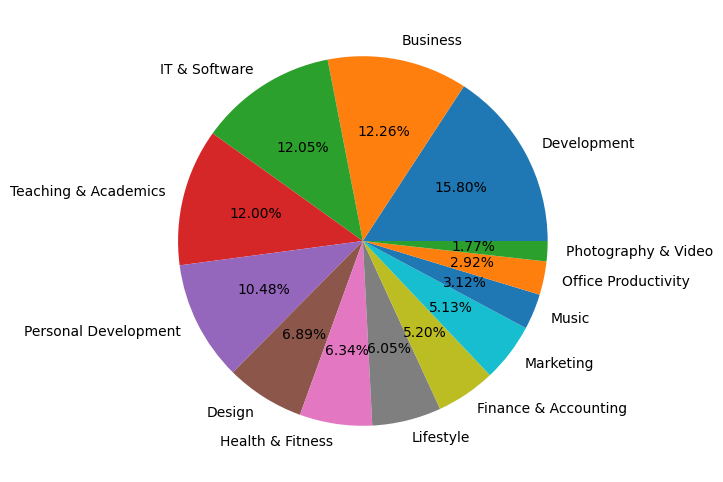

In [68]:
plt.figure(figsize=(6,6))
plt.pie(count_category,labels=count_category.index,autopct='%1.2f%%')
plt.show()

In [69]:
# df_fusionne[df_fusionne['category']=='IT & Software']['subcategory'].value_counts()
categories=df_fusionne['category'].value_counts().index.tolist()
subcatgories={x :[] for x in categories }

for x in categories:
    subcatgories[x]=df_fusionne[df_fusionne['category']==x]['subcategory'].value_counts().index.tolist()
subcatgories



{'Development': ['Web Development',
  'Programming Languages',
  'Data Science',
  'Mobile Development',
  'Game Development',
  'Database Design & Development',
  'Software Engineering',
  'Software Development Tools',
  'Software Testing',
  'No-Code Development'],
 'Business': ['Entrepreneurship',
  'Management',
  'Communication',
  'E-Commerce',
  'Business Analytics & Intelligence',
  'Project Management',
  'Sales',
  'Business Strategy',
  'Operations',
  'Human Resources',
  'Other Business',
  'Real Estate',
  'Industry',
  'Media',
  'Business Law'],
 'IT & Software': ['Other IT & Software',
  'Network & Security',
  'IT Certifications',
  'Operating Systems & Servers',
  'Hardware'],
 'Teaching & Academics': ['Language Learning',
  'Engineering',
  'Science',
  'Math',
  'Other Teaching & Academics',
  'Test Prep',
  'Teacher Training',
  'Online Education',
  'Humanities',
  'Social Science'],
 'Personal Development': ['Personal Transformation',
  'Career Development',
  '

In [70]:
df_fusionne.isnull().sum().sort_values(ascending=False)

level                 37053
content_length_min        0
published_date            0
instructor                0
topic                     0
subcategory               0
category                  0
last_update_date          0
id                        0
title                     0
num_comments              0
num_reviews               0
avg_rating                0
num_subscribers           0
headline                  0
price                     0
num_lectures              0
dtype: int64

In [71]:
df_fusionne.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115716 entries, 0 to 115715
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  115716 non-null  float64
 1   title               115716 non-null  object 
 2   price               115716 non-null  float64
 3   headline            115716 non-null  object 
 4   num_subscribers     115716 non-null  float64
 5   avg_rating          115716 non-null  float64
 6   num_reviews         115716 non-null  float64
 7   num_comments        115716 non-null  float64
 8   num_lectures        115716 non-null  float64
 9   content_length_min  115716 non-null  float64
 10  last_update_date    115716 non-null  object 
 11  category            115716 non-null  object 
 12  subcategory         115716 non-null  object 
 13  topic               115716 non-null  object 
 14  instructor          115716 non-null  object 
 15  published_date      115716 non-nul

In [72]:
df_fusionne['last_update_date'].head()

0    2020-11-06
1    2010-01-12
2    2019-10-09
3    2016-01-13
4    2011-06-23
Name: last_update_date, dtype: object

In [73]:
df_fusionne['level']=df_fusionne['level'].replace({"Expert":"Advanced"})
df_fusionne['level'].value_counts()

level
Beginner        32630
Advanced        29673
All Levels       9752
Intermediate     6608
Name: count, dtype: int64

In [74]:
#predire level
data_avec_level=df_fusionne[df_fusionne['level'].notna()]
data_sans_level=df_fusionne[df_fusionne['level'].isna()]

Transformer plusieurs colonnes textuelles brutes en un seul texte propre, exploitable TF-IDF

In [75]:
#pretraitement du texte
data_avec_level_copy=data_avec_level.copy()
#combiner les colonnes textuelles
data_avec_level_copy['description']=(
    data_avec_level_copy['title']+' '
    +data_avec_level_copy['headline']+' '
    +data_avec_level_copy['category']+' '
    +data_avec_level_copy['subcategory']+' '+
    data_avec_level_copy['topic'])
#1.
# data_avec_level_copy['description'].duplicated().sum()
data_avec_level_copy=data_avec_level_copy.drop_duplicates(subset='description',keep='first')
data_avec_level_copy['description'].duplicated().sum()

#2.lowercase 3.remove  speacial characteres
data_avec_level_copy['description_clean'] = (
    data_avec_level_copy['description']
    .str.lower()
    .str.replace(r'[^\w\s]', '', regex=True)#supprimer les points de ponctuations
    .str.replace(r'\s+', ' ', regex=True)#supprimer les espaces multiples
    .str.replace(r'\d+',' ',regex=True)#supprimer des chiffres
    .str.strip()
)

data_avec_level_copy['description_clean'].head()

1    the lean startup talk at stanford ecorner debu...
4    web design from the ground up learn web design...
5    navigating the mba admissions process mba admi...
7    beginners how to create iphone and ipad apps z...
8    ccnp route   video boot camp with chris bryant...
Name: description_clean, dtype: object

In [76]:
#pretraitement du texte
data_sans_level_copy=data_sans_level.copy()
#combiner les colonnes textuelles
data_sans_level_copy['description']=(
    data_sans_level_copy['title']+' '
    +data_sans_level_copy['headline']+' '
    +data_sans_level_copy['category']+' '
    +data_sans_level_copy['subcategory']+' '+
    data_sans_level_copy['topic'])

#1.
# data_avec_level_copy['description'].duplicated().sum()
data_sans_level_copy=data_sans_level_copy.drop_duplicates(subset='description',keep='first')
data_sans_level_copy['description'].duplicated().sum()




#2.lowercase 3.remove  speacial characteres
data_sans_level_copy['description_clean'] = (
    data_sans_level_copy['description']
    .str.lower()
    .str.replace(r'[^\w\s]', '', regex=True)#supprimer les points de ponctuations
    .str.replace(r'\s+', ' ', regex=True)#supprimer les espaces multiples
    .str.replace(r'\d+',' ',regex=True)#supprimer des chiffres
    .str.strip()
)

data_sans_level_copy['description_clean'].head()

0     online vegan vegetarian cooking school learn t...
2     how to become a vegan vegetarian or flexitaria...
3     how to train a puppy train your puppy the righ...
6     kundalini yoga to heal stress and anxiety by v...
14    ccnp tshoot     video boot camp with chris bry...
Name: description_clean, dtype: object

In [77]:
feature_cols=[col for col in data_avec_level.columns if col!='level']
text_cols=['title','headline','category','subcategory','topic']
other_cols=[col for col in feature_cols if col not in text_cols]
target_col='level'

X=data_avec_level_copy[feature_cols]
X_other=data_avec_level_copy[other_cols]
X_text=data_avec_level_copy[text_cols]
X_pred=data_avec_level_copy[feature_cols]
y=data_avec_level_copy[target_col]
other_cols

['id',
 'price',
 'num_subscribers',
 'avg_rating',
 'num_reviews',
 'num_comments',
 'num_lectures',
 'content_length_min',
 'last_update_date',
 'instructor',
 'published_date']

**Convert text to features**

In [78]:
vectorizer=TfidfVectorizer(stop_words='english',max_df=0.9,sublinear_tf=True)
X_tf=vectorizer.fit_transform(data_avec_level_copy['description_clean'])
#fit : le vectorizer apprend le vocabulaire,transform : il convertit chaque texte en un vecteur numérique
#stop_words='english' : Supprime automatiquement les mots très fréquents et peu informatifs comme : the, is, and
#max_df=0.9: Ignore les mots qui apparaissent dans plus de 90% des documents
#sublinear_tf=True Applique une transformation logarithmique sur la fréquence des mots :Les mots très fréquents dans un document ne dominent pas trop la représentation


In [79]:
cols_to_remove = ['instructor', 'course_url', 'language']
other_cols = [col for col in other_cols if col not in cols_to_remove]
other_cols

['id',
 'price',
 'num_subscribers',
 'avg_rating',
 'num_reviews',
 'num_comments',
 'num_lectures',
 'content_length_min',
 'last_update_date',
 'published_date']

In [80]:
X_tf.shape 
#chaque cours de data_avec_level_copy est une ligne et Chaque colonne correspond à une feature, c’est-à-dire un mot unique du vocabulaire

(78644, 38021)

In [81]:
#pour combiner le texte et les features numériques pour entraîner ton modèle ML.
X_other_numeric = X_other.select_dtypes(include=[np.number])

# Concaténer sparse + autres features numériques : concaténation horizontale 
X_full_sparse = hstack([
    X_tf,
    X_other_numeric.values.astype(np.float32)
], format='csr')

In [82]:
print(X_full_sparse.shape)
print(y.shape)
print(y.value_counts())


(78644, 38029)
(78644,)
level
Beginner        32619
Advanced        29666
All Levels       9752
Intermediate     6607
Name: count, dtype: int64


In [83]:
ordre_level = {'Beginner': 0,'Intermediate': 1,'Advanced': 2,'All Levels':3}

y_encoded = y.map(ordre_level)
y_encoded.isna().sum()
# car Les modèles ML (SVM, XGBoost…) ne comprennent que les nombres, pas le texte.y_encoded devient un vecteur d’entiers .

0

In [84]:
X_train, X_test, y_train, y_test = train_test_split(X_full_sparse,y_encoded,test_size=0.2,random_state=42,stratify=y_encoded)

In [85]:

model = LinearSVC(
    class_weight='balanced',
    random_state=42
)
print("Training model...")
model.fit(X_train, y_train)



Training model...


,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,verbose,0
,random_state,42


In [86]:
print(classification_report(
    y_test,
    model.predict(X_test),
    target_names=ordre_level.keys(),
    digits=3
))


              precision    recall  f1-score   support

    Beginner      0.473     0.611     0.533      6524
Intermediate      0.000     0.000     0.000      1321
    Advanced      0.384     0.340     0.361      5933
  All Levels      0.288     0.301     0.294      1951

    accuracy                          0.419     15729
   macro avg      0.286     0.313     0.297     15729
weighted avg      0.377     0.419     0.394     15729



ona une forte desequilibre de class: Même avec class_weight='balanced', LinearSVC n’arrive pas à corriger complètement ce déséquilibre.

Intermediate a un f1-score de 0.000 — le modèle ne la prédit presque jamais.

In [87]:
# On choisit XGBoost comme classifieur, plus robuste que SVM pour les données déséquilibrées et complexes.
#XGBoost est choisi car il est robuste aux classes déséquilibrées et capture les relations complexes non linéaires entre les features.

# 1. Vérifier ce qu'est ordre_level
print(f"\n1. Type de ordre_level: {type(ordre_level)}")
print(f"   Valeur: {ordre_level}")

# 2. Vérifier y_test
print(f"\n2. Valeurs uniques dans y_test: {np.unique(y_test)}")

# 3. Prendre les clés du dict, pas les valeurs!
if isinstance(ordre_level, dict):
    print("\n3. ordre_level est un dict, utiliser les clés comme noms de classes")
    target_names = list(ordre_level.keys())  
    print(f"   Clés (noms de classes): {list(ordre_level.keys())}")
    print(f"   Valeurs (encodage): {list(ordre_level.values())}")
    print(f"   Target names créés: {target_names}")
else:
    
    target_names = list(ordre_level)

print(f"\n4. Target names à utiliser: {target_names}")

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='mlogloss'
)

#n_estimators=100 → nombre d’arbres
#max_depth=6 → profondeur max des arbres
#learning_rate=0.1 → taux d’apprentissage
#eval_metric='mlogloss' → métrique adaptée au multi-class
#n_jobs=-1 : Utilise tous les cœurs de ton processeur pour accélérer l’entraînement.

print("\nEntraînement XGBoost...")
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("\nXGBoost Results:")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=target_names,  
    digits=3 #affiche score avec 3 chiffres apres virgule
))
# Distribution des prédictions
print("\nDistribution des prédictions XGBoost:")
unique_pred, counts_pred = np.unique(y_pred_xgb, return_counts=True)
for val, count in zip(unique_pred, counts_pred):
    percentage = count / len(y_pred_xgb) * 100
    label = target_names[val]
    print(f"  {label}: {count} ({percentage:.1f}%)")

print("\nDistribution réelle dans y_test:")
unique_true, counts_true = np.unique(y_test, return_counts=True)
for val, count in zip(unique_true, counts_true):
    percentage = count / len(y_test) * 100
    label = target_names[val]
    print(f"  {label}: {count} ({percentage:.1f}%)")


1. Type de ordre_level: <class 'dict'>
   Valeur: {'Beginner': 0, 'Intermediate': 1, 'Advanced': 2, 'All Levels': 3}

2. Valeurs uniques dans y_test: [0 1 2 3]

3. ordre_level est un dict, utiliser les clés comme noms de classes
   Clés (noms de classes): ['Beginner', 'Intermediate', 'Advanced', 'All Levels']
   Valeurs (encodage): [0, 1, 2, 3]
   Target names créés: ['Beginner', 'Intermediate', 'Advanced', 'All Levels']

4. Target names à utiliser: ['Beginner', 'Intermediate', 'Advanced', 'All Levels']

Entraînement XGBoost...

XGBoost Results:
              precision    recall  f1-score   support

    Beginner      0.850     0.829     0.839      6524
Intermediate      0.744     0.490     0.591      1321
    Advanced      0.784     0.859     0.819      5933
  All Levels      0.502     0.513     0.507      1951

    accuracy                          0.772     15729
   macro avg      0.720     0.673     0.689     15729
weighted avg      0.773     0.772     0.770     15729


Distributio

In [88]:
df_fusionne['level'].value_counts().sum()

78663

In [89]:
data_sans_level.shape

(37053, 17)

In [90]:
data_sans_level_copy = data_sans_level.copy()

data_sans_level_copy['description'] = (
    data_sans_level_copy['title'] + ' '
    + data_sans_level_copy['headline'] + ' '
    + data_sans_level_copy['category'] + ' '
    + data_sans_level_copy['subcategory'] + ' '
    + data_sans_level_copy['topic']
)

data_sans_level_copy['description_clean'] = (
    data_sans_level_copy['description']
    .str.lower()
    .str.replace(r'[^\w\s]', '', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.replace(r'\d+', ' ', regex=True)
    .str.strip()
)

X_tf_sans = vectorizer.transform(
    data_sans_level_copy['description_clean']
)

X_other_numeric = X_other.select_dtypes(include=[np.number])

X_other_sans = data_sans_level_copy[other_cols]
X_other_numeric_sans = X_other_sans.select_dtypes(include=[np.number])

assert X_other_numeric_sans.shape[1] == X_other_numeric.shape[1]
X_sans_level_sparse = hstack(
    [
        X_tf_sans,
        X_other_numeric_sans.values.astype(np.float32)
    ],
    format='csr'
)
y_pred_sans = xgb_model.predict(X_sans_level_sparse)
data_sans_level_copy['level_pred'] = y_pred_sans
data_sans_level_copy['level'] = data_sans_level_copy['level_pred'].apply(
    lambda x: target_names[x]
)

data_sans_level_copy.drop(columns=['level_pred'], inplace=True)

data_finale = pd.concat(
    [data_avec_level_copy, data_sans_level_copy],
    axis=0,
    ignore_index=True
)
print(data_finale['level'].value_counts())
print(data_finale['level'].isna().sum())


level
Advanced        64191
Beginner        33247
All Levels      11603
Intermediate     6656
Name: count, dtype: int64
0


In [91]:
data_finale.isna().sum()

id                    0
title                 0
price                 0
headline              0
num_subscribers       0
avg_rating            0
num_reviews           0
num_comments          0
num_lectures          0
content_length_min    0
last_update_date      0
category              0
subcategory           0
topic                 0
instructor            0
published_date        0
level                 0
description           0
description_clean     0
dtype: int64

In [92]:
data_finale.shape

(115697, 19)

In [93]:
data_finale.to_csv('Udemy_courses_final.csv',index=False)

<h1>clustering</h1>

# TF-IDF (Term Frequency – Inverse Document Frequency)

##  Objectif
TF-IDF est une méthode de **vectorisation de texte** qui permet de transformer des documents textuels en **représentations numériques**, afin de pouvoir les exploiter dans des algorithmes de machine learning (clustering, classification, similarité).

L’idée principale est de donner plus d’importance :
- aux mots **fréquents dans un document**
- mais **rares dans l’ensemble du corpus**

---

TF-IDF repose sur deux composantes :

###  Term Frequency (TF)
Mesure la fréquence d’un terme dans un document donné.

$$
TF(t, d) = \frac{\text{Nombre d’occurrences du terme } t \text{ dans } d}
{\text{Nombre total de mots dans } d}
$$

Plus un mot apparaît dans un document, plus son **TF** augmente.

---

### Inverse Document Frequency (IDF)
Mesure l’importance globale d’un terme dans le corpus.

$$
IDF(t) = \log(\frac{N}{1 + df(t)})
$$

- $N$ : nombre total de documents  
- $df(t)$ : nombre de documents contenant le terme $t$

 Les mots très fréquents dans tous les documents sont **pénalisés**.

---

###  TF-IDF
La pondération finale est donnée par :

$$
TF\text{-}IDF(t, d) = TF(t, d) \times IDF(t)
$$

 Un terme est considéré comme important s’il est :
- fréquent dans un document
- rare dans le corpus
---


##  Silhouette Score

### Principe
Le Silhouette Score mesure à quel point chaque point est bien assigné à son cluster par rapport aux autres clusters.

Pour un point donné \(i\), le score de silhouette est défini par :

$$
s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}
$$

où :
- \(a(i)\) est la distance moyenne entre le point \(i\) et les autres points du **même cluster**  
- \(b(i)\) est la distance moyenne entre le point \(i\) et les points du **cluster le plus proche**

---

### Interprétation
- **\(s(i) ≈ 1\)** : le point est bien clusterisé  
- **\(s(i) ≈ 0\)** : le point est à la frontière entre deux clusters  

Le **Silhouette Score global** est la moyenne de \(s(i)\) sur l’ensemble des points.

**Plus le score est élevé, meilleure est la qualité du clustering.**



In [94]:
def optimized_clustering_pipeline(df):
    # 2. Features numériques
    numerical_features = [
        'price', 'num_subscribers', 'avg_rating', 
        'num_reviews', 'num_lectures', 'content_length_min'
    ]
    X_numerical = df[numerical_features].copy()
    scaler = MinMaxScaler()
    X_num_scaled = scaler.fit_transform(X_numerical)

    categorical_features = ['category', 'subcategory', 'topic', 'level']

    ohe = OneHotEncoder(
        sparse_output=False,          # pour pouvoir faire np.hstack
        handle_unknown='ignore'
    )

    X_cat_ohe = ohe.fit_transform(df[categorical_features])
    
    # 4. Features textuelles (UNIQUEMENT title + headline)
    print("\n Extraction features textuelles (title + headline)...")
    df['text_content'] = (
        df['title']+ ' ' + 
        df['headline']
    ).str.lower().str.strip()
    
    tfidf = TfidfVectorizer(
        max_features=1000,
        stop_words='english',
        ngram_range=(1, 2),
        min_df=3,
        max_df=0.85
    )
    X_text = tfidf.fit_transform(df['text_content'])
    X_text_dense = X_text.toarray()
    print(f" Shape: {X_text_dense.shape}")
    
    # 5. Combinaison avec pondérations optimisées
    print("\n Combinaison des features...")
    X_combined = np.hstack([
        X_num_scaled ,  
        X_cat_ohe ,   
        X_text_dense  
    ])
    print(f" Shape finale: {X_combined.shape}")
    # 6. PCA
    print("\n Réduction PCA...")
    pca = PCA(n_components=0.90)  # 95% variance
    X_pca = pca.fit_transform(X_combined)
    print(f" Dimensions: {X_combined.shape[1]} → {X_pca.shape[1]}")
    print(f" Variance expliquée: {pca.explained_variance_ratio_.sum():.4f}")
    # 7. Recherche du meilleur k
    best_k = None
    best_sil = -1
    
    for k in range(3, 11):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_pca)
        sil = silhouette_score(X_pca, labels)
        
        print(f"k={k}: Silhouette={sil:.4f}")
        
        if sil > best_sil:
            best_sil = sil
            best_k = k
    
    print(f"\n Meilleur k: {best_k} (Silhouette: {best_sil:.4f})")
    
    # 8. Clustering final avec meilleur k
    kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    labels_final = kmeans_final.fit_predict(X_pca)
    # Évaluation finale
    print("Resultats:")
    sil_final = silhouette_score(X_pca, labels_final)
    
    print(f"Silhouette Score: {sil_final:.4f}")
    
    return {
        'X_pca': X_pca,
        'X_text': X_text_dense,
        'pca': pca,
        'kmeans': kmeans_final,
        'labels': labels_final,
        'best_k': best_k,
        'tfidf': tfidf,
        'metrics': {
            'silhouette': sil_final
        }
    }
results = optimized_clustering_pipeline(data_finale)


 Extraction features textuelles (title + headline)...
 Shape: (115697, 1000)

 Combinaison des features...
 Shape finale: (115697, 4793)

 Réduction PCA...
 Dimensions: 4793 → 1248
 Variance expliquée: 0.9000
k=3: Silhouette=0.1087
k=4: Silhouette=0.0742
k=5: Silhouette=0.0648
k=6: Silhouette=0.0668
k=7: Silhouette=0.0925
k=8: Silhouette=0.0670
k=9: Silhouette=0.0709
k=10: Silhouette=0.0866

 Meilleur k: 3 (Silhouette: 0.1087)
Resultats:
Silhouette Score: 0.1087


In [95]:
results['metrics'], results['best_k']

({'silhouette': 0.10872574891904672}, 3)

In [99]:
def find_course_index(df, title_query):
    titles = df['title']
    
    mask = titles.str.contains(title_query, case=False)
    if mask.sum() == 1:
        return df[mask].index[0]
    
    # Plusieurs résultats → meilleur match
    if mask.sum() > 1:
        return df[mask].index[0]
    # dans le cas de faute de frappe de titre ou des mots manquants comme "Python Beginners" et "Python For Beginners"
    matches = get_close_matches(title_query, titles, n=1, cutoff=0.6) # cutoff est seuil de similarité et il est entre 0 et 1
    if matches:
        return df[df['title'] == matches[0]].index[0]
    
    raise ValueError(f"Cours introuvable : '{title_query}'")

In [100]:
def recommend_by_cluster_general(
    df,
    labels,
    course_title,
    n_recommendations=10,
    verbose=True
):
    # 1. Trouver le cours source
    course_idx = find_course_index(df, course_title)
    course = df.loc[course_idx]
    cluster_id = labels[course_idx]
    
    # 2. Filtrer le cluster
    candidates = df[(labels == cluster_id) & (df.index != course_idx)].copy()
    
    # 3. Similarity score
    candidates['similarity_score'] = (
        (candidates['subcategory'] == course['subcategory']).astype(int) * 30 +
        (candidates['topic'] == course['topic']).astype(int) * 20 +
        (candidates['level'] == course['level']).astype(int) * 15 +
        (candidates['avg_rating'] / 5) * 20 +
        (candidates['num_subscribers'] /
         candidates['num_subscribers'].max()) * 15 +
         (np.abs(candidates['price'] - course['price']) < 20).astype(int) * 10
    )

    # 4. Top-K
    recommendations = candidates.nlargest(n_recommendations, 'similarity_score')
    #nlargest: retourne les n plus grandes valeurs d'une colonne spécifiée, dans notre cas 'similarity_score'
    # 5. Affichage optionnel
    if verbose:
        print(" COURS SOURCE")
        print(f" title: {course['title']} | Cluster {cluster_id}")
        print(f" categorie:{course['category']}, subcategory:  {course['subcategory']}, topic: {course['topic']}")
        
        print("\n Recommandation:\n" )
        for i, (_, c) in enumerate(recommendations.iterrows(), 1):
            print(f"{i}. title: {c['title']}  rating: {c['avg_rating']:.2f}  num subscribers: {int(c['num_subscribers']):,}")

    
    return recommendations


In [101]:
recs = recommend_by_cluster_general(
    df=data_finale,
    labels=results['labels'],
    course_title="Web Design from the Ground Up",
    n_recommendations=10
)

 COURS SOURCE
 title: Web Design from the Ground Up | Cluster 0
 categorie:Design, subcategory:  Web Design, topic: Web Design

 Recommandation:

1. title: HTML Essential Training : 5 Ways to Semantically Code HTML  rating: 4.79  num subscribers: 360
2. title: Web design masterclass for absolute beginners  rating: 5.00  num subscribers: 4
3. title: Learn Figma for Web Design, User Interface, UI UX in an hour  rating: 4.57  num subscribers: 31,480
4. title: HTML CSS JavaScript for Beginners Modern Web Design Course  rating: 4.55  num subscribers: 5,125
5. title: Web Design -Your Own Website in Just 5 Hours -Even Beginners  rating: 4.55  num subscribers: 1,980
6. title: WYSIWYG Web Builder Layout Grid Essential Training  rating: 4.50  num subscribers: 85
7. title: CREATE A CHURCH WEBSITE: A-Z Web Design For Total Beginners!  rating: 4.50  num subscribers: 68
8. title: Psychology Driven UX/UI/Web Design - PART 1 Fundamentals  rating: 4.45  num subscribers: 608
9. title: Beginner Guide To 